# Notebook 1 – Distribution Analysis

## Mục tiêu

Notebook này khảo sát đặc điểm của tập dữ liệu khuôn mặt đã thu thập trước khi tiến hành đánh giá mô hình nhận diện.

Nội dung gồm 4 phần:
1. Tổng quan và kiểm tra dữ liệu.
2. Phân phối số lượng ảnh theo điều kiện.
3. Phân tích độ sáng hình ảnh.
4. Phân tích kích thước khuôn mặt.

## 1. Import thư viện

Sử dụng Pandas để xử lý dữ liệu và Matplotlib, Seaborn để trực quan hóa.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Thiết lập giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Đọc dữ liệu

Đọc file `metadata.csv` chứa thông tin của các ảnh đã thu thập.

**Lưu ý:** File metadata hiện tại không có dòng tiêu đề, vì vậy ta tự đặt tên cho 7 cột.

In [3]:
# Tìm file metadata theo vị trí tương đối của notebook
data_path = Path("../data/collected/metadata.csv")
if not data_path.exists():
    data_path = Path("data/collected/metadata.csv")

# Đặt tên cho các cột trong file CSV
columns = [
    "filename", "condition", "timestamp",
    "face_width", "face_height", "brightness", "confidence"
]

# Đọc dữ liệu và chuyển timestamp sang kiểu ngày giờ
df = pd.read_csv(data_path, header=None, names=columns)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

display(df.head())

,filename,condition,timestamp,face_width,face_height,brightness,confidence
0,normal_0001.jpg,normal,2026-11-11 00:51:25,174,222,97.59,0.9997
1,normal_0002.jpg,normal,2026-11-11 00:51:29,175,217,100.65,0.9998
2,normal_0003.jpg,normal,2026-11-11 00:51:29,165,199,104.85,0.9999
3,normal_0004.jpg,normal,2026-11-11 00:51:30,171,210,102.94,1.0000
4,normal_0005.jpg,normal,2026-11-11 00:51:30,169,217,102.31,0.9993


## 3. Tổng quan và kiểm tra dữ liệu

Kiểm tra số dòng, số cột, kiểu dữ liệu, thống kê cơ bản và giá trị bị thiếu để nắm được cấu trúc tập dữ liệu.

In [4]:
# Kích thước của tập dữ liệu
print("Kích thước tập dữ liệu:", df.shape)

# Kiểm tra kiểu dữ liệu và số lượng giá trị không rỗng
df.info()

# Thống kê cơ bản các cột dạng số
display(df.describe())

# Kiểm tra giá trị bị thiếu và tên file trùng lặp
print("\nSố lượng giá trị bị thiếu:")
display(df.isnull().sum())
print("Số lượng tên file bị trùng:", df["filename"].duplicated().sum())

Kích thước tập dữ liệu: (160, 7)
<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   filename     160 non-null    str           
 1   condition    160 non-null    str           
 2   timestamp    160 non-null    datetime64[us]
 3   face_width   160 non-null    int64         
 4   face_height  160 non-null    int64         
 5   brightness   160 non-null    float64       
 6   confidence   160 non-null    float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(2)
memory usage: 8.9 KB


,timestamp,face_width,face_height,brightness,confidence
count,160,160.000000,160.000000,160.000000,160.000000
mean,2026-11-11 00:52:38.418750,164.712500,212.237500,103.749125,0.997771
min,2026-11-11 00:51:25,96.000000,111.000000,84.270000,0.936900
25%,2026-11-11 00:52:01.500000,133.000000,196.000000,93.375000,0.999475
50%,2026-11-11 00:52:44,164.000000,209.500000,100.635000,0.999950
75%,2026-11-11 00:53:16,176.000000,223.500000,104.947500,1.000000
max,2026-11-11 00:53:50,278.000000,328.000000,158.970000,1.000000
std,NaN,47.683757,52.794783,15.570518,0.007096



Số lượng giá trị bị thiếu:


filename       0
condition      0
timestamp      0
face_width     0
face_height    0
brightness     0
confidence     0
dtype: int64

Số lượng tên file bị trùng: 0


## 4. Phân phối số lượng ảnh theo điều kiện

Tập dữ liệu được thu thập trong 8 điều kiện: normal, low_light, bright, near, far, left, right và expression.

Phần này kiểm tra số lượng ảnh ở mỗi điều kiện để xem dữ liệu có được phân bố tương đối đồng đều hay không.

,Số lượng hình ảnh
condition,
bright,20
expression,20
far,20
left,20
low_light,20
near,20
normal,20
right,20


Tổng số hình ảnh: 160


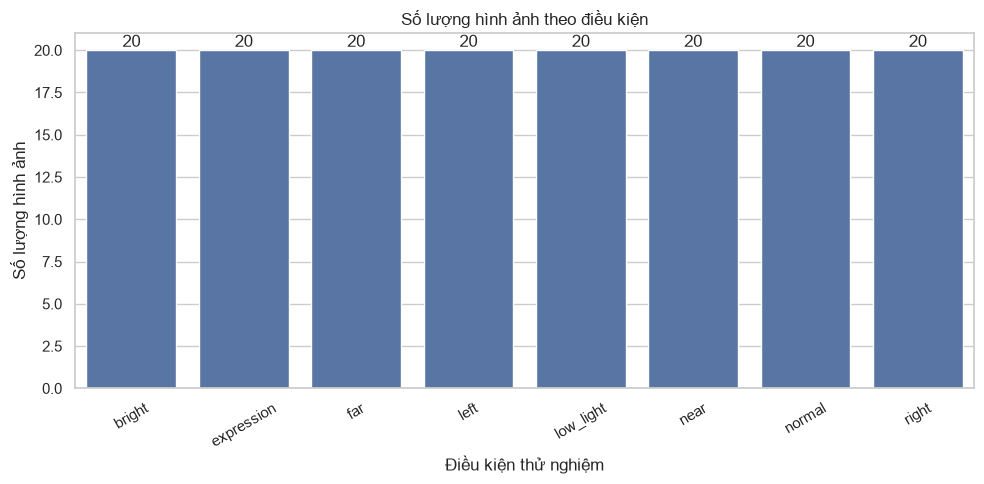

In [5]:
# Đếm số lượng ảnh trong từng điều kiện
condition_counts = df["condition"].value_counts().sort_index()
display(condition_counts.to_frame(name="Số lượng hình ảnh"))
print("Tổng số hình ảnh:", len(df))

# Vẽ biểu đồ số lượng ảnh theo điều kiện
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=condition_counts.index, y=condition_counts.values)

plt.title("Số lượng hình ảnh theo điều kiện")
plt.xlabel("Điều kiện thử nghiệm")
plt.ylabel("Số lượng hình ảnh")
plt.xticks(rotation=30)

# Hiển thị số lượng trên đầu mỗi cột
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

## 5. Phân tích độ sáng hình ảnh

Cột `brightness` lưu giá trị độ sáng trung bình của vùng khuôn mặt được phát hiện.

Sử dụng biểu đồ boxplot để so sánh mức độ phân bố độ sáng giữa các điều kiện, đặc biệt là điều kiện thiếu sáng và ánh sáng mạnh.

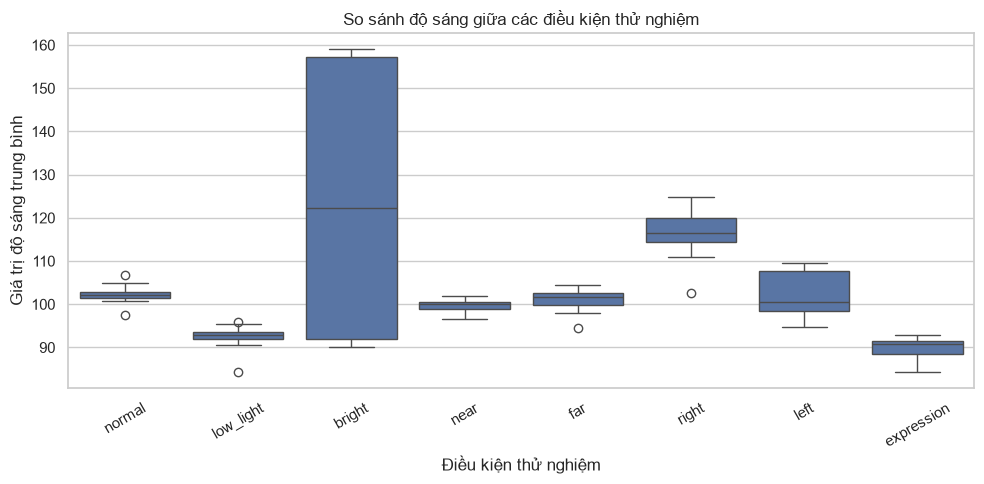

In [6]:
# So sánh độ sáng giữa các điều kiện
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="condition", y="brightness")

plt.title("So sánh độ sáng giữa các điều kiện thử nghiệm")
plt.xlabel("Điều kiện thử nghiệm")
plt.ylabel("Giá trị độ sáng trung bình")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Nhận xét

- Quan sát vị trí trung vị và độ trải rộng của từng boxplot để so sánh độ sáng giữa các điều kiện.
- Điều kiện `low_light` thường có độ sáng thấp hơn, trong khi `bright` thường có độ sáng cao hơn.
- Nhận xét cuối cùng cần dựa trên biểu đồ thực tế của tập dữ liệu.

## 6. Phân tích kích thước khuôn mặt

Kích thước khuôn mặt được ước lượng bằng diện tích bounding box, tính từ chiều rộng nhân với chiều cao vùng khuôn mặt được phát hiện.

So sánh diện tích bounding box trung bình giữa các điều kiện giúp quan sát ảnh hưởng của khoảng cách đến camera. Đây là diện tích tính theo pixel, không phải kích thước thực tế của khuôn mặt.

,Diện tích trung bình (pixel²)
condition,
bright,39722.85
expression,39295.90
far,11498.75
left,25237.85
low_light,32896.00
near,86240.45
normal,36577.80
right,27381.70


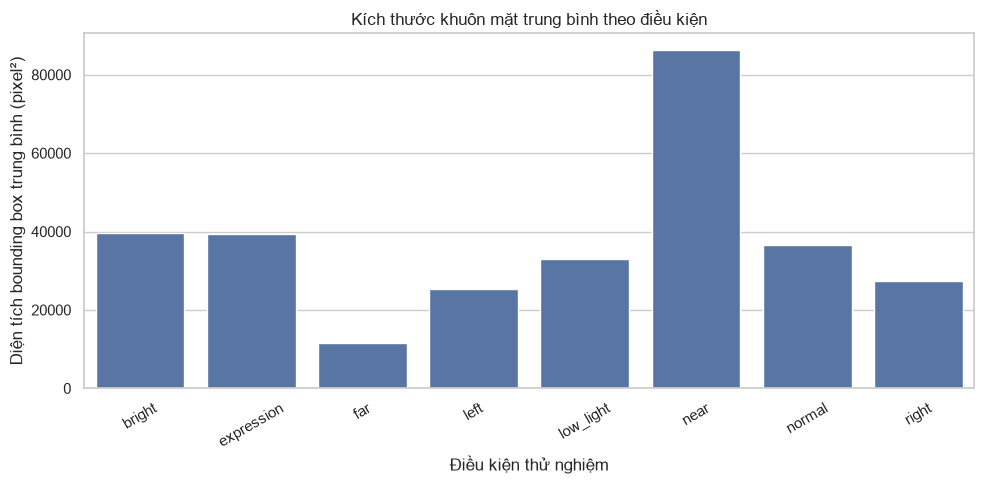

In [7]:
# Tính diện tích bounding box của khuôn mặt
df["face_area"] = df["face_width"] * df["face_height"]

# Tính diện tích trung bình theo từng điều kiện
face_size = df.groupby("condition")["face_area"].mean().sort_index()
display(face_size.to_frame(name="Diện tích trung bình (pixel²)"))

# Vẽ biểu đồ so sánh kích thước khuôn mặt
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=face_size.index, y=face_size.values)

plt.title("Kích thước khuôn mặt trung bình theo điều kiện")
plt.xlabel("Điều kiện thử nghiệm")
plt.ylabel("Diện tích bounding box trung bình (pixel²)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Nhận xét

- Diện tích bounding box lớn hơn cho thấy vùng khuôn mặt chiếm nhiều pixel hơn trong ảnh.
- Khi ở gần camera, khuôn mặt thường chiếm diện tích lớn hơn so với khi ở xa.
- Kết quả có thể thay đổi do góc quay đầu và độ chính xác của bước phát hiện khuôn mặt.

## 7. Kết luận

Notebook đã khảo sát tập dữ liệu thông qua số lượng ảnh theo từng điều kiện, độ sáng và kích thước vùng khuôn mặt được phát hiện.

Các kết quả này giúp hiểu rõ đặc điểm dữ liệu đầu vào và làm cơ sở cho bước đánh giá mô hình nhận diện khuôn mặt ở notebook tiếp theo.